# Experiment: Anonymizers AggFace

This notebook analyzes the results from running the `anonymizers_aggface` experiment.

In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
from matplotlib import pyplot as plt

from meles.paths import repository_root

sns.set_theme(style="whitegrid")

ROOT = repository_root()
IMAGES = ROOT / "images"
RESULTS = ROOT / "results" / "anonymizers_aggface.parquet"

ANONYMIZERS = ["none", "gaussianblur", "pixelation", "blackbar"]
# Which leg AggFace (8 frames per reconstruction) ran on; the other leg used no frame aggregation.
AGGREGATED_ON = ["neither", "gallery", "samples", "both"]

results = pd.read_parquet(RESULTS)
identities = results["identity"].nunique()
chance = 1 / identities
print(f"{RESULTS.relative_to(ROOT)}: {len(results):,} rows, {identities} identities, chance top-1 = {chance:.4f}")

results/anonymizers_aggface.parquet: 1,843,072 rows, 600 identities, chance top-1 = 0.0017


In [2]:
def label(frame: pd.DataFrame) -> pd.DataFrame:
    """Name the samples' anonymization 'anonymizer' and tag each row with the legs AggFace ran on."""
    frame = frame.rename(columns={"samples_frame_anonymizer": "anonymizer"})
    # Aggregator keys are '{scope}_{method}'; only the method says whether AggFace ran on that leg.
    gallery_agg = frame["gallery_frame_aggregator"].str.split("_", n=1).str[1] != "none"
    samples_agg = frame["samples_frame_aggregator"].str.split("_", n=1).str[1] != "none"
    frame["aggregated on"] = np.select(
        [gallery_agg & samples_agg, gallery_agg, samples_agg], ["both", "gallery", "samples"], default="neither"
    )
    frame["anonymizer"] = pd.Categorical(frame["anonymizer"], ANONYMIZERS)
    frame["aggregated on"] = pd.Categorical(frame["aggregated on"], AGGREGATED_ON)
    return frame


# Gallery and samples anonymized the same way.
matched = label(results[results["samples_frame_anonymizer"] == results["gallery_frame_anonymizer"]])

# Every cell should hold the same query videos, otherwise the conditions are scored on different people.
matched.groupby(["score_aggregator", "anonymizer", "aggregated on"], observed=True).size().unstack()

aggregated on                  neither  gallery  samples   both
score_aggregator anonymizer                                    
max_mean         none            14399    14399    14399  14399
                 gaussianblur    14399    14399    14399  14399
                 pixelation      14399    14399    14399  14399
                 blackbar        14399    14399    14399  14399
max_none         none            14399    14399    14399  14399
                 gaussianblur    14399    14399    14399  14399
                 pixelation      14399    14399    14399  14399
                 blackbar        14399    14399    14399  14399

## Where to aggregate: gallery, samples, both or neither

Top-1 when AggFace reconstructs faces on the gallery (per identity and fold), on the samples (per video), on both, or on neither. Here gallery and samples carry the same anonymization. Shown for both scores: `max_none` decides per observation, `max_mean` averages the similarities over each query video first. Each identity counts once: its videos are averaged first, and the whiskers are a 95% bootstrap interval over identities.

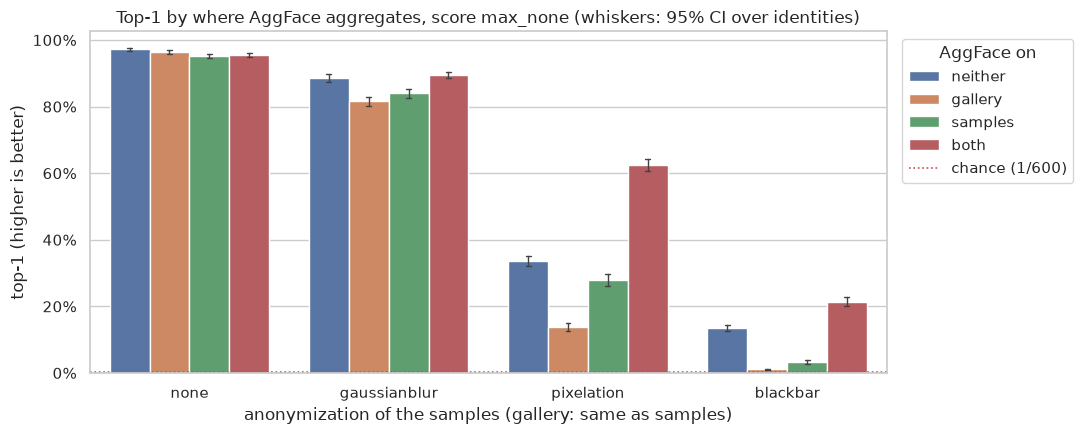

aggregated on,neither,gallery,samples,both
anonymizer,,,,
none,97.199997,96.400002,95.300003,95.599998
gaussianblur,88.599998,81.599998,84.000000,89.599998
pixelation,33.700001,13.900000,27.900000,62.400002
blackbar,13.400000,1.100000,3.300000,21.400000


In [3]:
def plot_aggregated_on(frame: pd.DataFrame, score: str, gallery: str, name: str) -> pd.DataFrame:
    """
    Bar plot of top-1 per anonymizer and leg AggFace ran on, saved to images/09_aggregated_on_{name}.png.

    :param frame: Rows labelled by `label`
    :param score: The score aggregator to show
    :param gallery: How the gallery was anonymized, for the axis label
    :param name: The figure's file name suffix
    :return: Top-1 in percent, anonymizer by leg
    """
    per_identity = (
        frame[frame["score_aggregator"] == score]
        .groupby(["anonymizer", "aggregated on", "identity"], observed=True)["top-1"]
        .mean()
        .reset_index()
    )

    fig, axis = plt.subplots(figsize=(11, 4.5))
    sns.barplot(
        per_identity,
        x="anonymizer",
        y="top-1",
        hue="aggregated on",
        order=ANONYMIZERS,
        hue_order=AGGREGATED_ON,
        errorbar=("ci", 95),
        n_boot=1000,
        seed=0,
        capsize=0.1,
        err_kws={"linewidth": 1},
        ax=axis,
    )
    axis.axhline(chance, color="#C44E52", linestyle=":", linewidth=1.2, label=f"chance (1/{identities})")
    axis.set_xlabel(f"anonymization of the samples (gallery: {gallery})")
    axis.set_ylabel("top-1 (higher is better)")
    axis.yaxis.set_major_formatter(lambda value, _: f"{value:.0%}")
    axis.grid(axis="x", visible=False)
    axis.legend(title="AggFace on", loc="upper left", bbox_to_anchor=(1.01, 1))
    axis.set_title(f"Top-1 by where AggFace aggregates, score {score} (whiskers: 95% CI over identities)")
    fig.tight_layout()
    fig.savefig(IMAGES / f"09_aggregated_on_{name}.png", dpi=150)
    plt.show()

    return per_identity.pivot_table(
        index="anonymizer", columns="aggregated on", values="top-1", observed=True
    ).mul(100).round(1)


plot_aggregated_on(matched, "max_none", "same as samples", "matched_max_none")

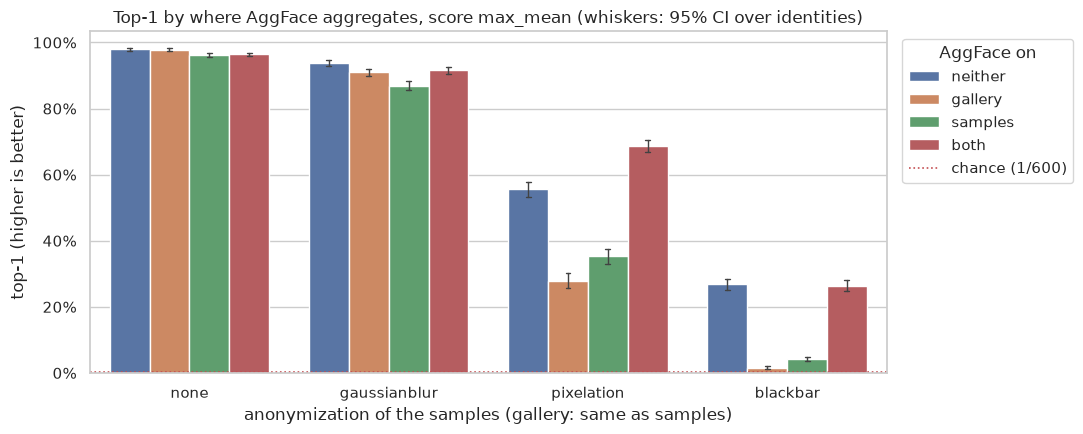

aggregated on,neither,gallery,samples,both
anonymizer,,,,
none,98.000000,97.800003,96.300003,96.400002
gaussianblur,93.900002,91.000000,86.900002,91.500000
pixelation,55.500000,27.900000,35.299999,68.800003
blackbar,26.900000,1.500000,4.200000,26.400000


In [4]:
plot_aggregated_on(matched, "max_mean", "same as samples", "matched_max_mean")

## The same against a clear gallery

The same comparison when the attacker holds clear footage (`none`) and only the samples are anonymized. The `none` group is the same pairing as in the plots above. "Gallery" here means AggFace reconstructing faces from frames that were never anonymized.

In [5]:
# Clear gallery, samples under every anonymization.
clear = label(results[results["gallery_frame_anonymizer"] == "none"])
clear.groupby(["score_aggregator", "anonymizer", "aggregated on"], observed=True).size().unstack()

aggregated on                  neither  gallery  samples   both
score_aggregator anonymizer                                    
max_mean         none            14399    14399    14399  14399
                 gaussianblur    14399    14399    14399  14399
                 pixelation      14399    14399    14399  14399
                 blackbar        14399    14399    14399  14399
max_none         none            14399    14399    14399  14399
                 gaussianblur    14399    14399    14399  14399
                 pixelation      14399    14399    14399  14399
                 blackbar        14399    14399    14399  14399

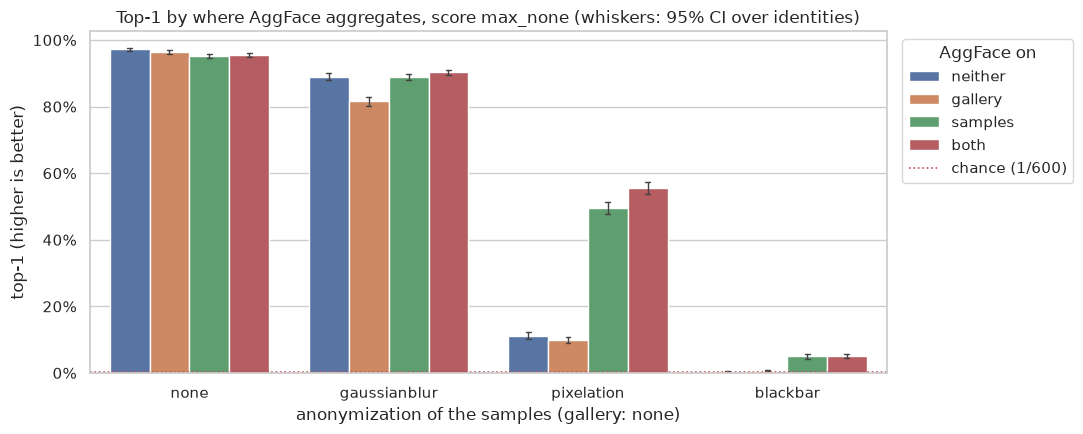

aggregated on,neither,gallery,samples,both
anonymizer,,,,
none,97.199997,96.400002,95.300003,95.599998
gaussianblur,89.000000,81.699997,89.000000,90.300003
pixelation,11.200000,9.800000,49.500000,55.500000
blackbar,0.300000,0.700000,5.000000,5.100000


In [6]:
plot_aggregated_on(clear, "max_none", "none", "clear_max_none")

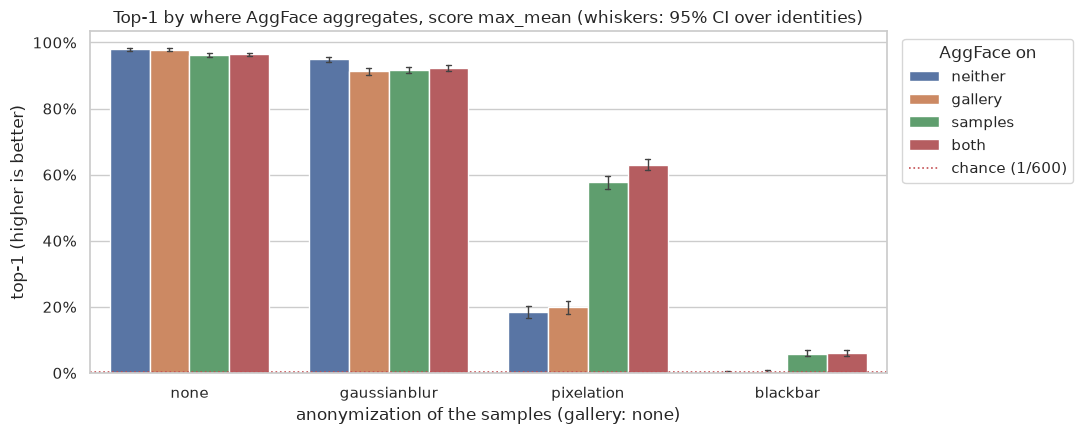

aggregated on,neither,gallery,samples,both
anonymizer,,,,
none,98.000000,97.800003,96.300003,96.400002
gaussianblur,94.900002,91.300003,91.800003,92.300003
pixelation,18.400000,19.799999,57.700001,63.000000
blackbar,0.200000,0.700000,5.900000,6.100000


In [7]:
plot_aggregated_on(clear, "max_mean", "none", "clear_max_mean")